# Model evaluation

The first notebook checked that the data and model files are what we say they are. This one asks how good the
detector really is, and how far the numbers can be trusted. Everything is computed from files committed in this
repository, so it reruns offline in a few seconds. The figures are also saved as PNG, SVG and PDF in `figures/`, each
with the CSV table behind it.

**How a photo is scored.** The detector runs on the whole photo, and each class keeps its best box confidence. The
photo's call is the class with the highest score, or *no detection* when no box reaches 0.25, the same cut the live
feed uses. Every proportion carries a 95% Wilson interval, which stays sensible near 0% and 100%.

**Two photo sets.**

| Set | Photos | Where from | Seen in training? |
|---|---|---|---|
| Farm test | 679 | Zenodo 4628934, the held-out 10% of the training collection | No, but same farms and visits |
| Lab-confirmed (PCR) | 1,255 | Zenodo 5801834, a separate collection whose labels were confirmed by PCR | No |

The detector is the default close-up model, `models/dropping4-laptop`, at 640 pixels.

In [1]:
import pandas as pd
from IPython.display import Image, display
import hc_viz as hv
import evaluation as ev

hv.style()
pd.set_option("display.precision", 3)
farm, pcr = ev.scored("farm_test_predictions"), ev.scored("pcr_predictions")
show = lambda name: display(Image(filename=str(ev.FIGURES / f"{name}.png"), width=900))
print(f"farm test {len(farm)} photos, lab-confirmed {len(pcr)} photos")

farm test 679 photos, lab-confirmed 1255 photos


## 1. Training: measured, not read by eye

The first notebook could only read the training curves from images. The per-epoch logs are now committed, so the
curves below are drawn from `results.csv`.

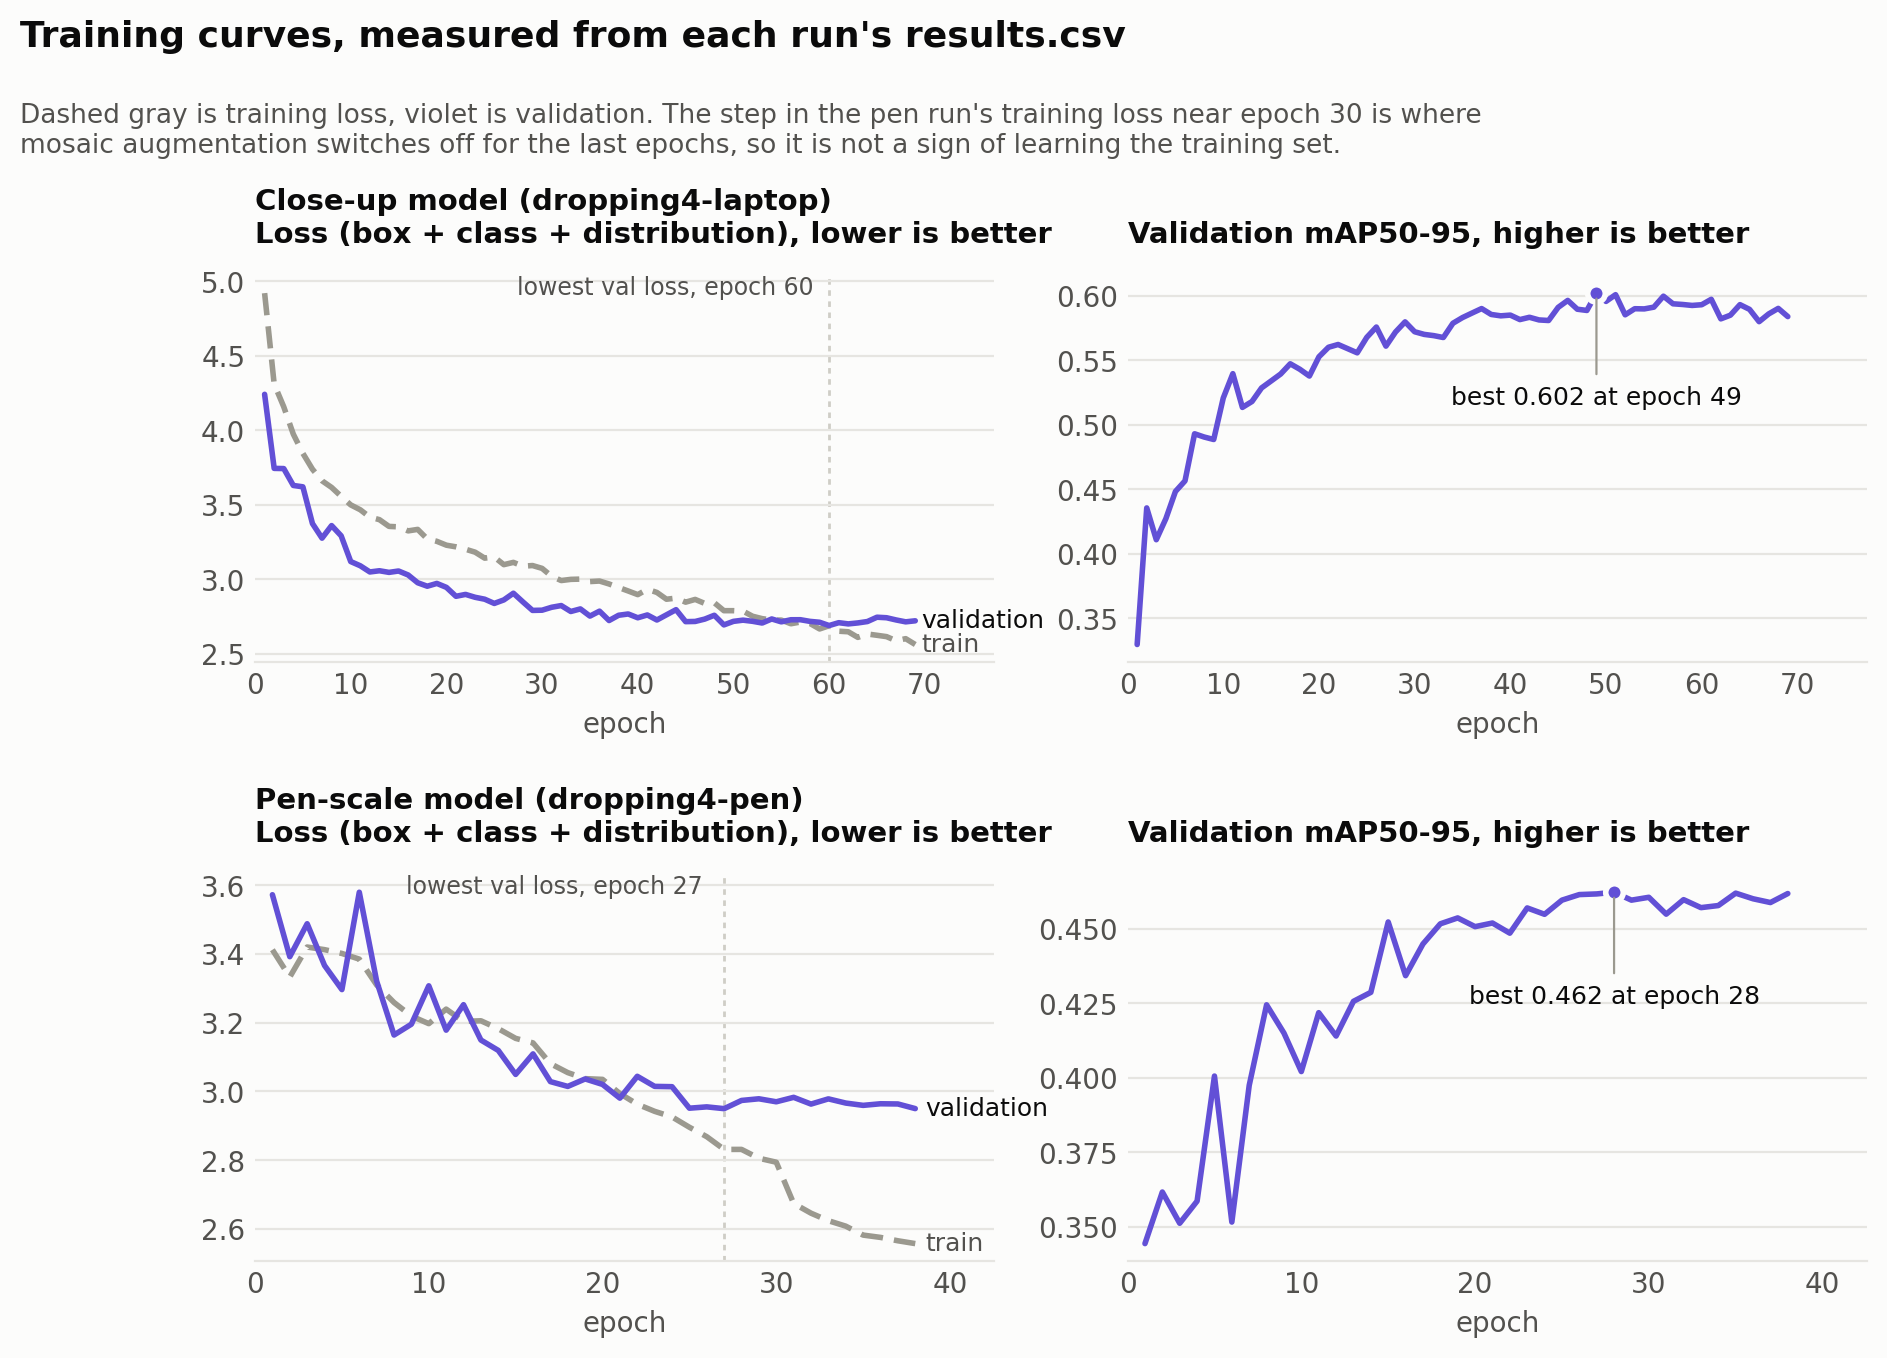

,epochs,best epoch (val mAP50-95),best val mAP50-95,lowest val loss epoch,val loss at end vs lowest,train loss at end vs lowest
run,,,,,,
Close-up model (dropping4-laptop),69,49,0.602,60,0.032,0.0
Pen-scale model (dropping4-pen),38,28,0.462,27,0.000,0.0


In [2]:
t = ev.fig_training(); show("05_training_curves"); t

**Reading.** In both runs validation loss stops improving while training loss keeps falling, which is the
usual start of overfitting. Early stopping keeps the best validation epoch (49 for the close-up model, 28 by
mAP50-95 for the pen model), so the shipped weights come from before the gap opens. The pen run's sharp drop in
training loss at epoch 31 happens when mosaic augmentation switches off for the last 10 planned epochs (`close_mosaic:
10` of 40 in its `args.yaml`). Validation does not follow, so it is not a real gain.

## 2. The headline: farm test against new photos

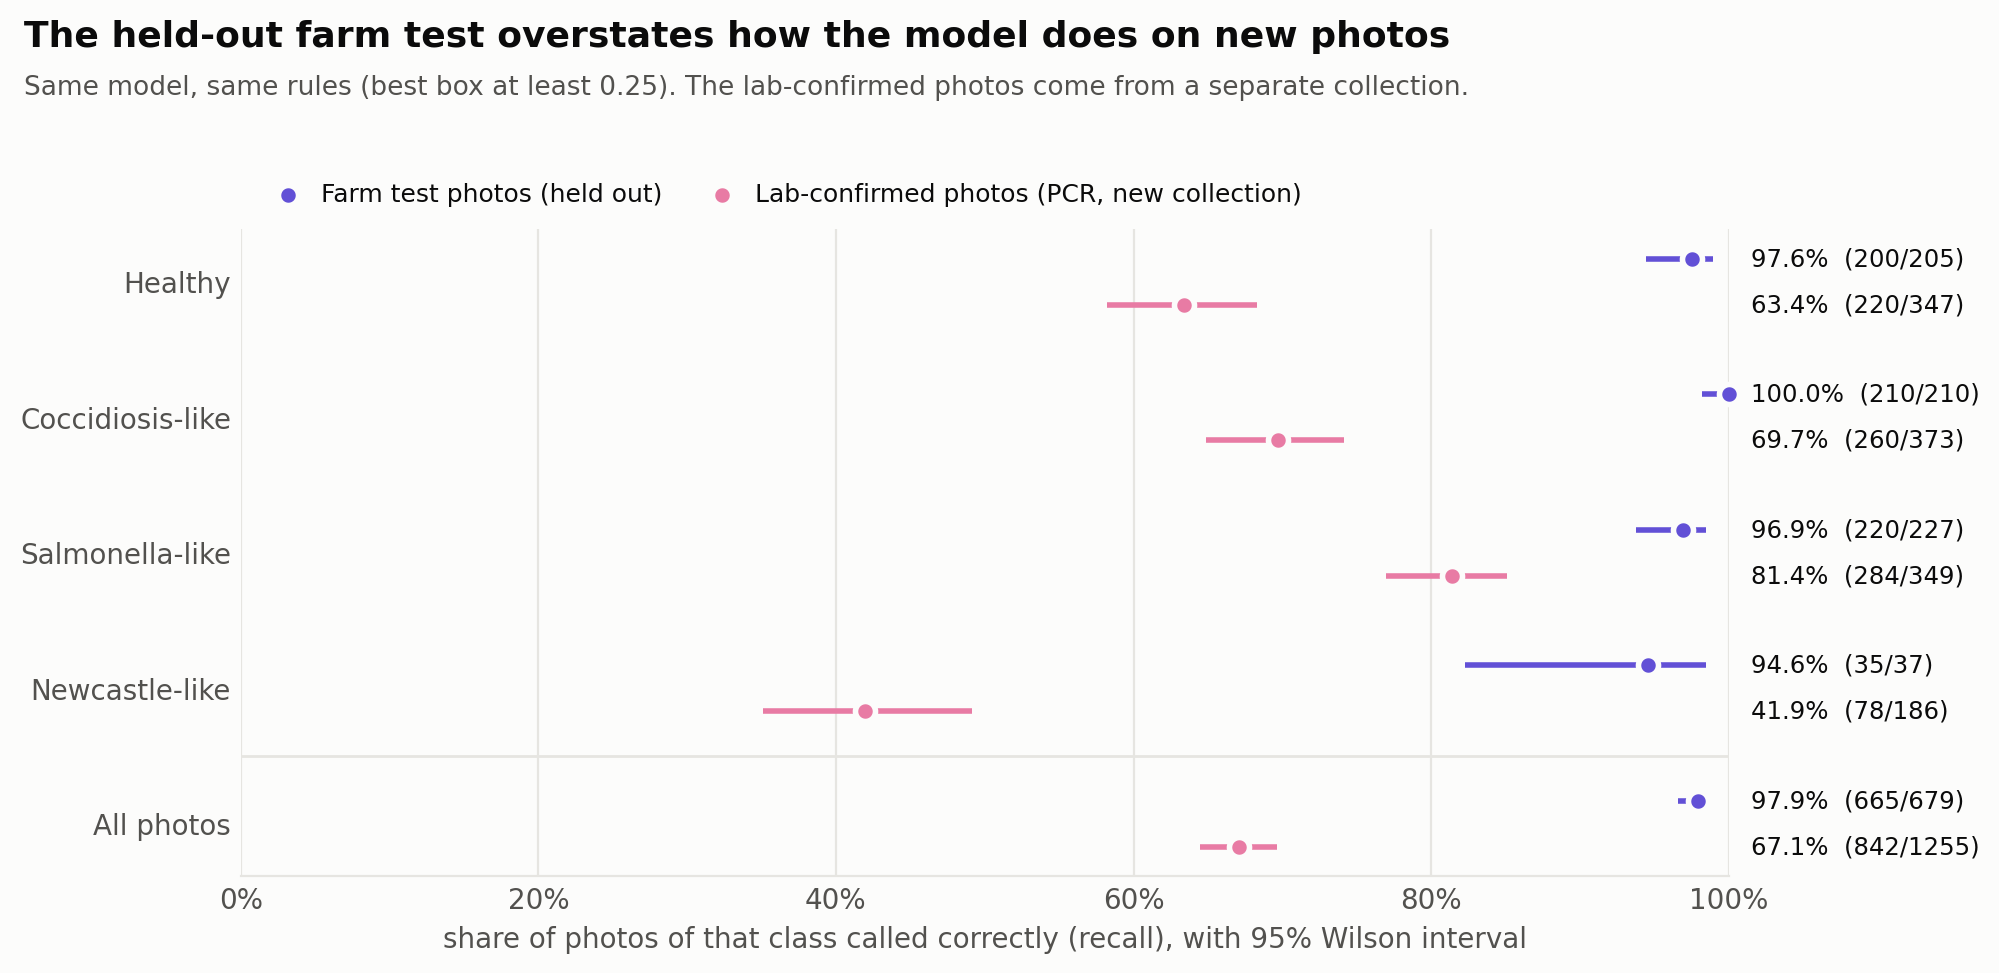

recall        ci_low        ci_high       
set       farm    pcr   farm    pcr    farm    pcr
class                                             
all      0.979  0.671  0.966  0.644   0.988  0.696
cocci    1.000  0.697  0.982  0.649   1.000  0.741
healthy  0.976  0.634  0.944  0.582   0.990  0.683
ncd      0.946  0.419  0.823  0.351   0.985  0.491
salmo    0.969  0.814  0.938  0.770   0.985  0.851

In [3]:
t = ev.fig_recall(farm, pcr); show("07_recall_by_class"); t.pivot(index="class", columns="set", values=["recall", "ci_low", "ci_high"]).round(3)

**Reading.** On held-out farm photos the model calls 97.9% of photos right (95% CI 96.6 to 98.8%). On the
lab-confirmed photos from a separate collection it calls 67.1% right (64.4 to 69.6%). The intervals are far apart,
so this is not noise. Newcastle-like drops the most, to 41.9%. It is also the class with by far the fewest photos
(376 in the whole collection, against over 2,000 for each of the others). **The farm test number describes photos like the training photos, not photos in general.** That is the number
to quote with care.

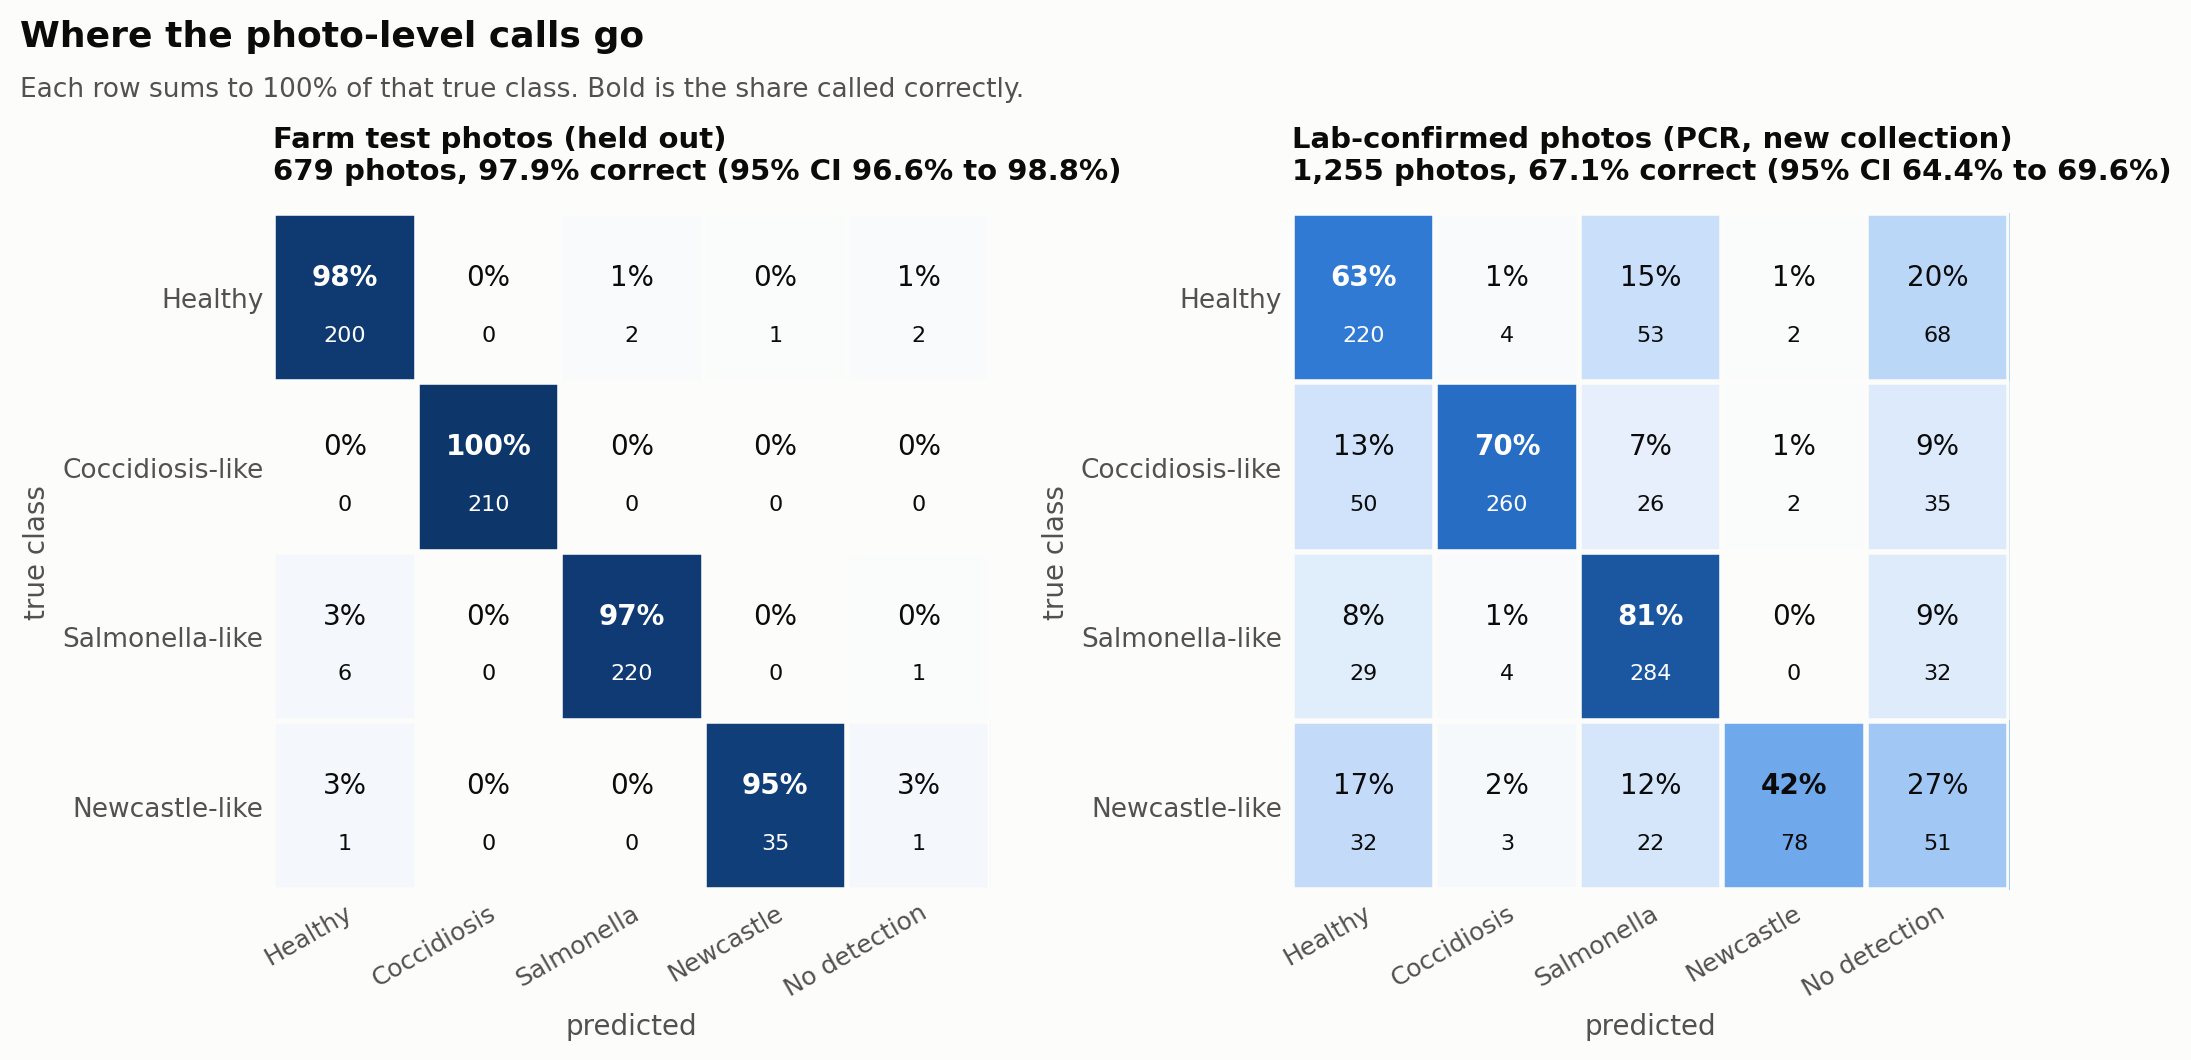

In [4]:
t = ev.fig_confusion(farm, pcr); show("06_confusion_matrices")

**Reading.** On the new photos most errors are not swaps between diseases. They are photos called *healthy* or
*salmonella-like* by mistake, and photos with no detection at all (20% of healthy, 27% of Newcastle-like). Healthy
photos in the training set show the dropping small in the frame (notebook 1, median 2.6% of the photo against 12 to
22% for the others). Different framing in the new collection is one likely reason for the misses, but this
notebook does not prove it.

## 3. Can the model say when it is unsure?

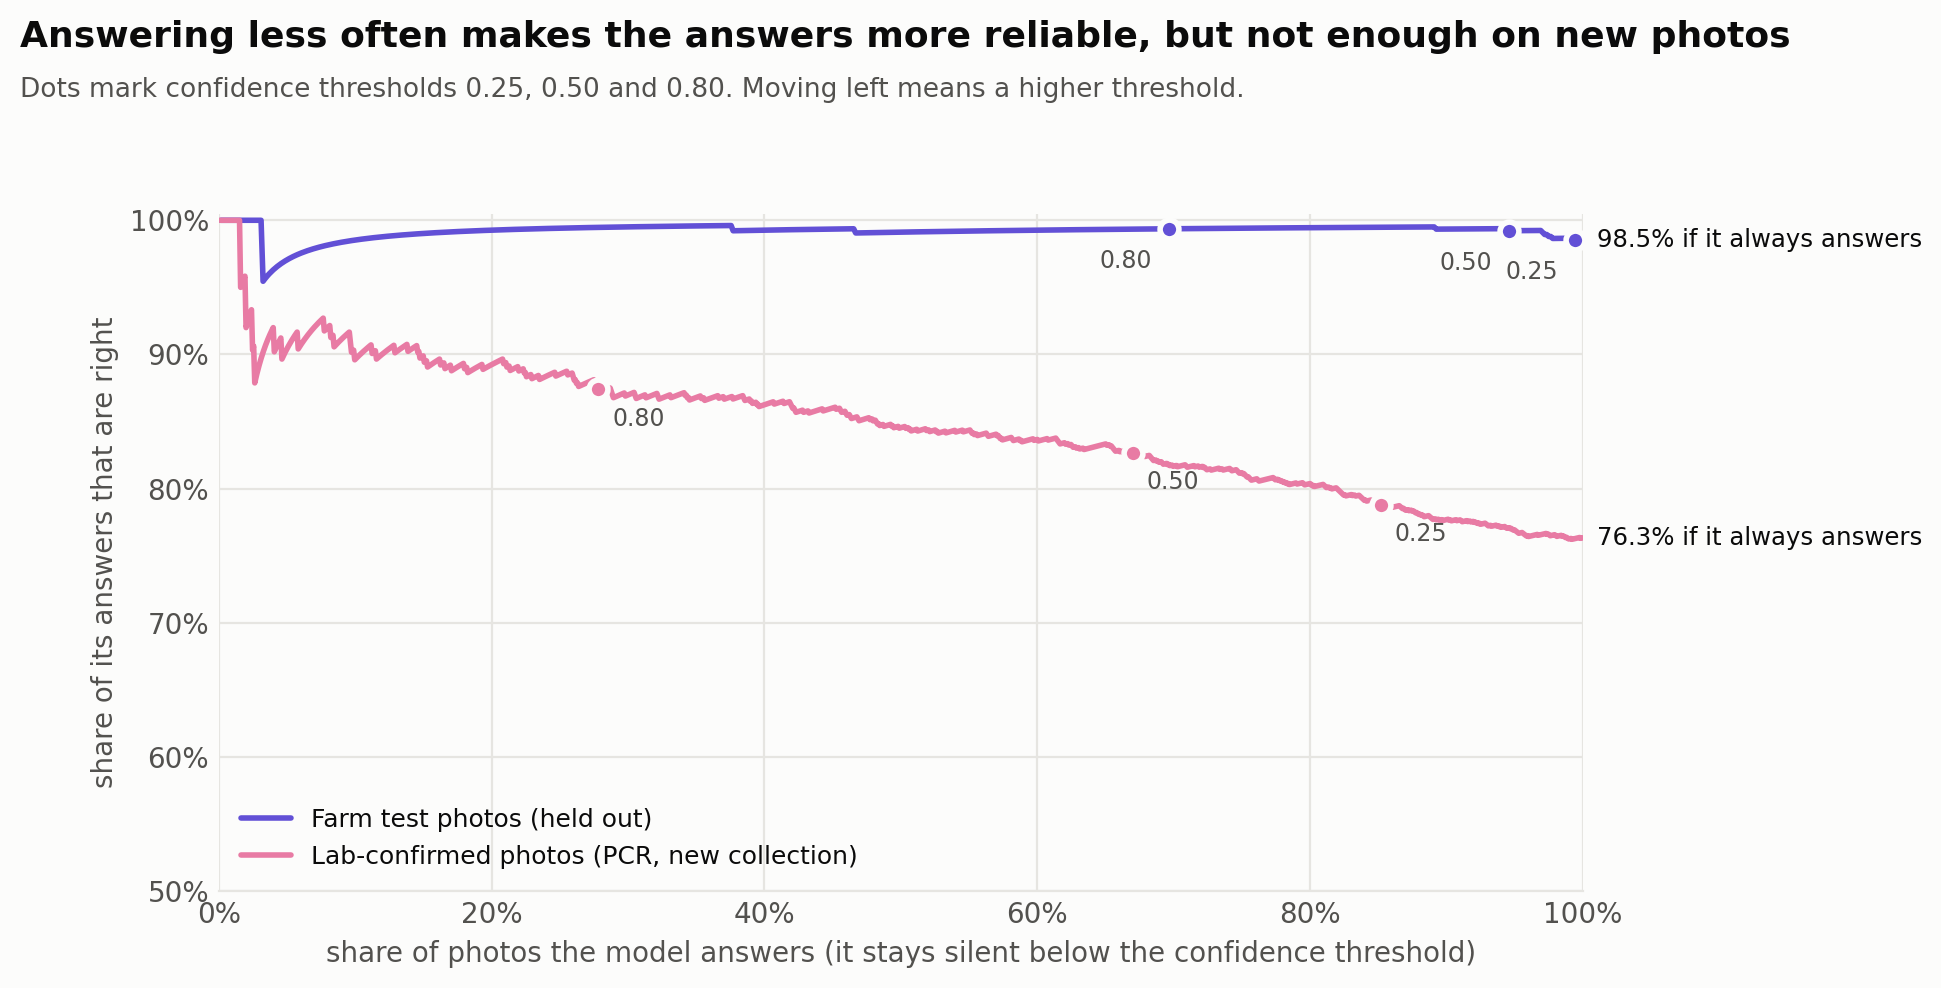

,set,threshold,answered,accuracy of answers
0,farm,0.25,0.994,0.985
1,farm,0.50,0.946,0.992
2,farm,0.80,0.697,0.994
3,pcr,0.25,0.852,0.788
4,pcr,0.50,0.670,0.826
5,pcr,0.80,0.278,0.874


In [5]:
t = ev.fig_coverage(farm, pcr); show("08_accuracy_vs_coverage"); t

**Reading.** If the model only answers when its best box clears a threshold, its answers get more reliable. On
new photos, raising the threshold from 0.25 to 0.80 lifts accuracy of the answers from 78.8% to 87.4%, but it then
answers only 27.8% of photos. A higher threshold does not close the gap to the farm test. It is a fair way to make
the alerts quieter and more trustworthy, at the cost of asking a person to look at more photos.

Note that the right end of each curve (the model always answers, no threshold) is higher than section 2. There a
photo under 0.25 counts as wrong, here it keeps its best guess.

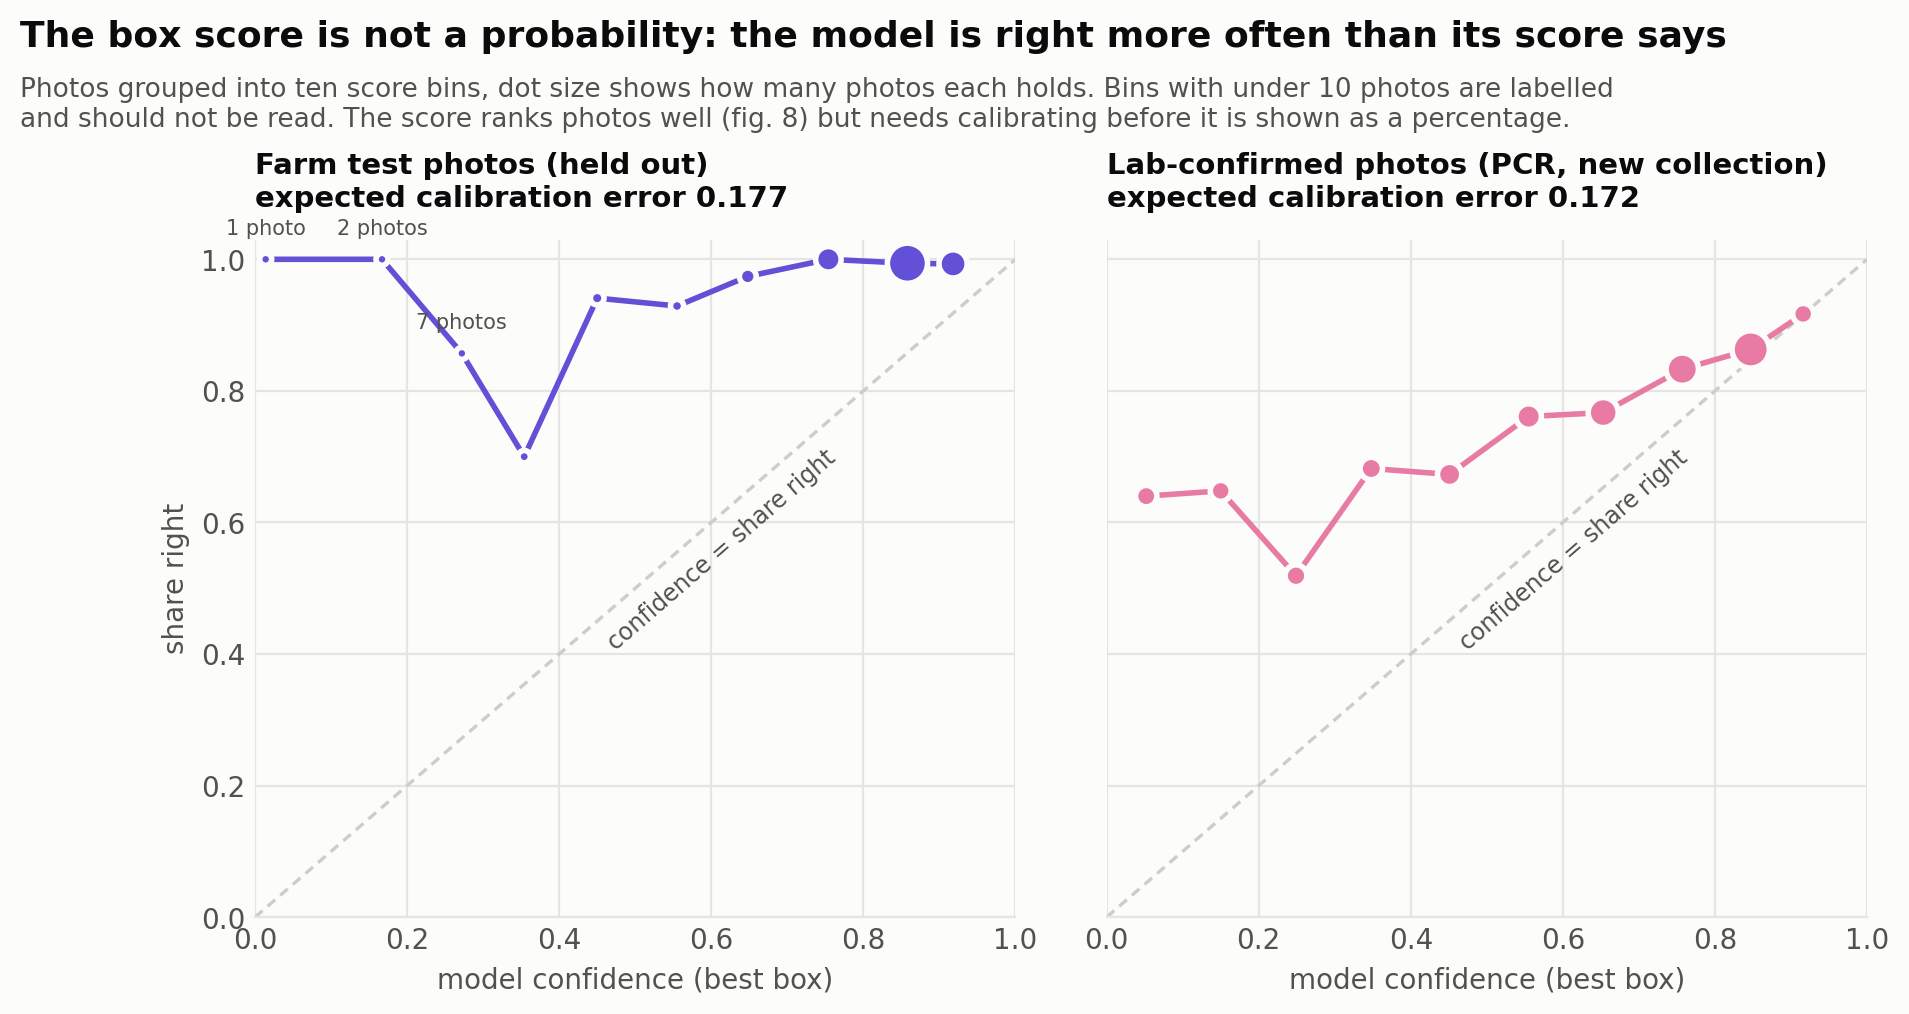

photos        mean confidence        accuracy       
set       farm    pcr            farm    pcr     farm    pcr
bin                                                         
0.0-0.1    1.0   75.0           0.014  0.052    1.000  0.640
0.1-0.2    2.0   71.0           0.167  0.150    1.000  0.648
0.2-0.3    7.0   79.0           0.272  0.249    0.857  0.519
0.3-0.4   10.0   85.0           0.354  0.348    0.700  0.682
0.4-0.5   17.0  104.0           0.450  0.451    0.941  0.673
0.5-0.6   14.0  117.0           0.555  0.555    0.929  0.761
0.6-0.7   38.0  172.0           0.648  0.653    0.974  0.767
0.7-0.8  117.0  203.0           0.754  0.757    1.000  0.833
0.8-0.9  325.0  277.0           0.858  0.847    0.994  0.863
0.9-1.0  148.0   72.0           0.918  0.916    0.993  0.917

In [6]:
t = ev.fig_calibration(farm, pcr); show("09_calibration"); t[t.bin != "ECE"].pivot(index="bin", columns="set", values=["photos", "mean confidence", "accuracy"])

**Reading.** Both curves sit above the diagonal: when the best box says 0.6, the photo is right more than 60% of
the time. So the box score is a ranking, not a probability. It must not be shown to a farmer as "60% sure" without
calibrating it first, for example by fitting a temperature or isotonic map on the validation split. Bins with under
10 photos are labelled in the chart and should not be read.

## 4. Are test photos also in training?

The split is random by photo, so the same picture saved twice could land on both sides. Every farm photo was reduced
to a 256-bit difference hash (`audit_images.py farm`). For each test photo the chart shows how many bits differ from
its closest training photo.

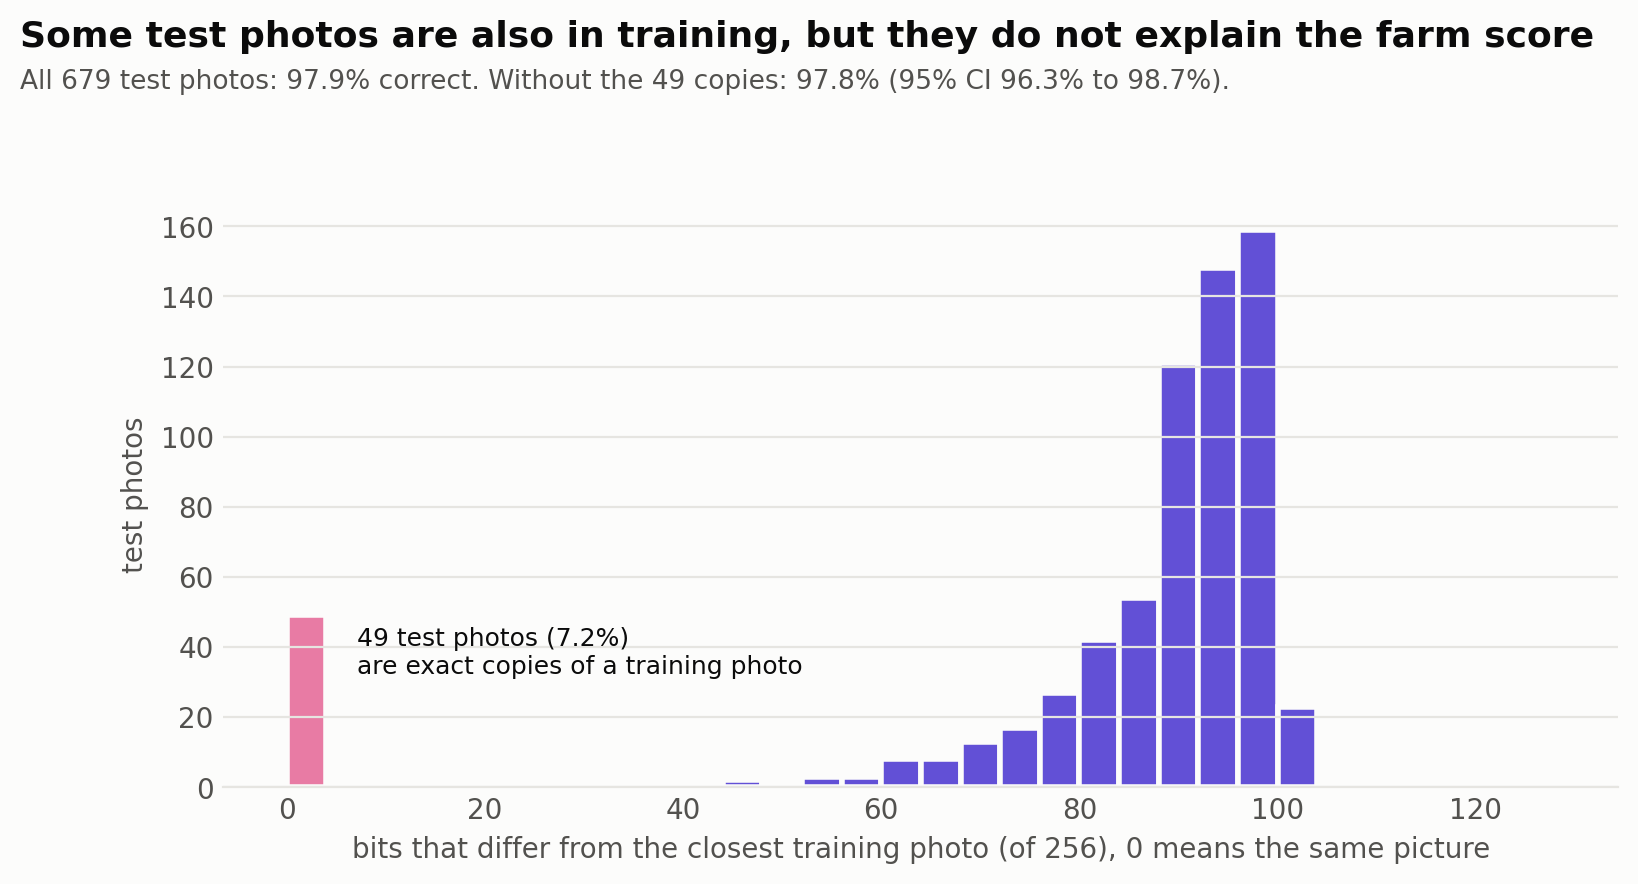

,photos,correct,accuracy,ci_low,ci_high
test photos,,,,,
all,679,665,0.979,0.966,0.988
exact copies of a training photo,49,49,1.000,NaN,NaN
without the copies,630,616,0.978,0.963,0.987


exact copies by class:


cls
healthy     1
cocci      19
salmo      29
ncd         0
Name: count, dtype: int64

In [7]:
t = ev.fig_duplicates(farm); show("10_duplicates_across_split"); display(t); print("exact copies by class:"); t.attrs["by_class"]

**Reading.** 49 test photos (7.2%) are exact copies of a training photo. The closest pair is saved in
`figures/pairs/` and is the same image under two file names. The copies are all called right, but removing them
barely moves the score (97.9% to 97.8%), so they are not what makes the farm number high. The bigger issue is the
one section 2 shows: the farm test shares farms and visits with training, while the new collection does not.

Fix for the next training run: drop exact duplicates before splitting, and split by visit or farm if the publisher
can provide it.

## 5. Pen scale and the live clip

The close-up model was built on photos where the dropping fills the frame. In a pen camera a dropping is a few pixels
wide. `dropping4-pen` is a fine-tune on pen-scale views, tested on cameras it never saw in training.

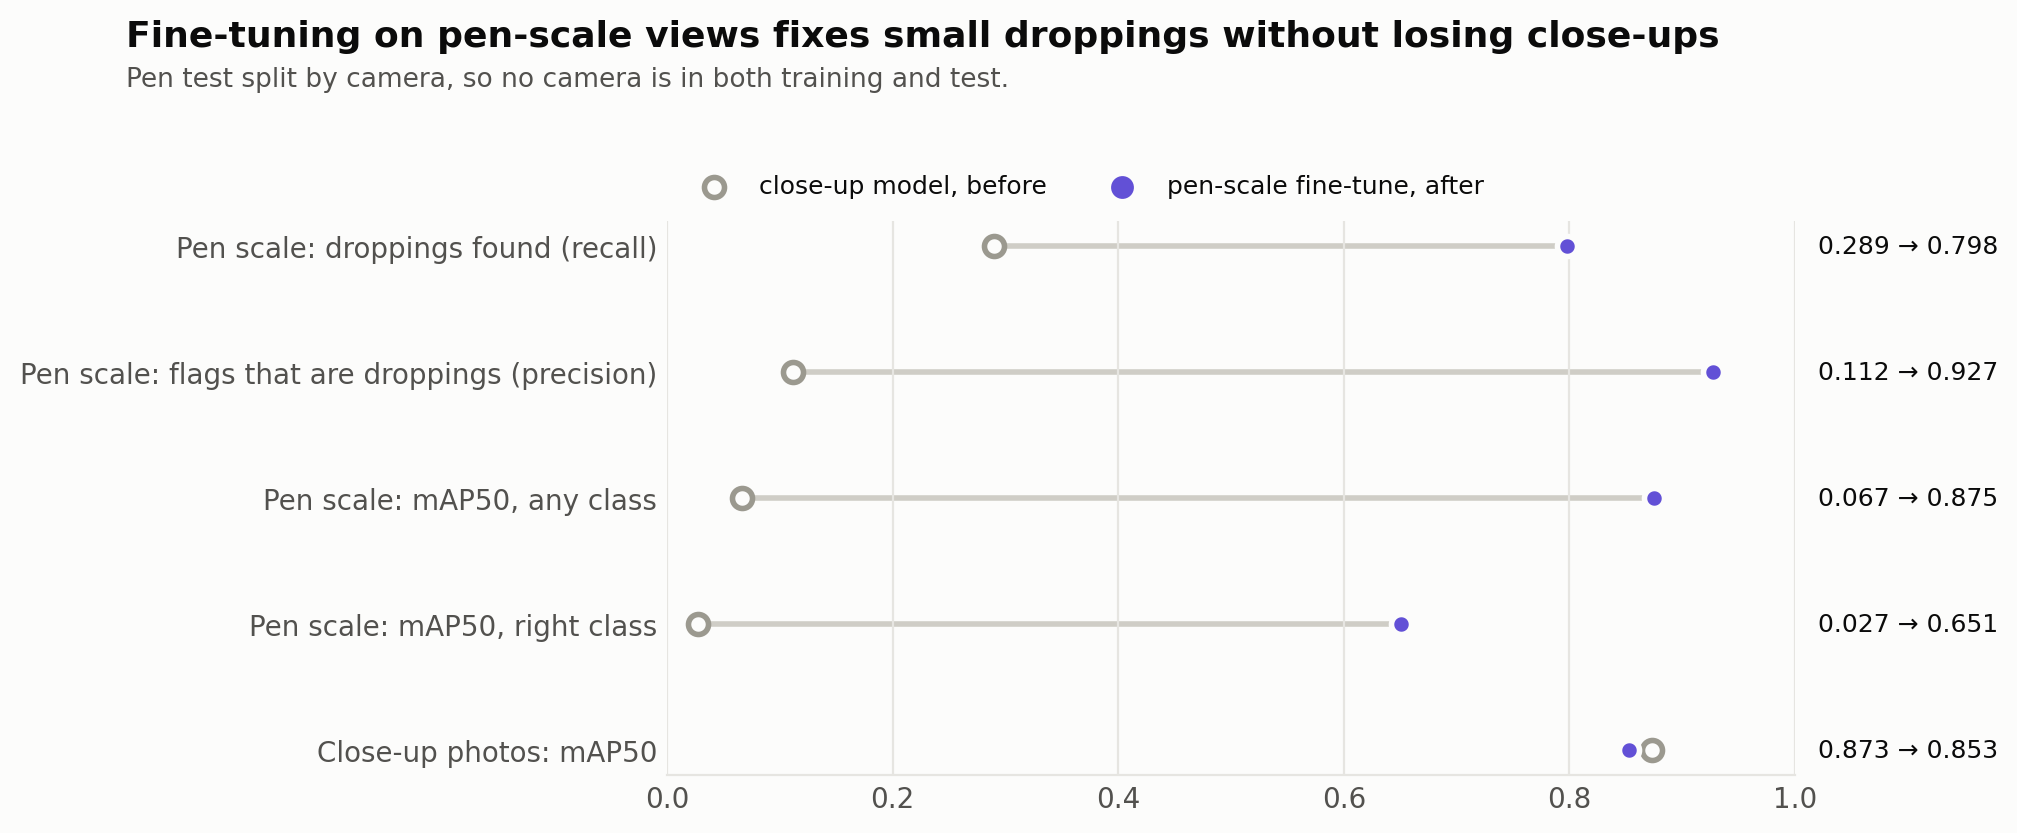

,before,after
metric,,
Pen scale: droppings found (recall),0.289,0.798
Pen scale: flags that are droppings (precision),0.112,0.927
"Pen scale: mAP50, any class",0.067,0.875
"Pen scale: mAP50, right class",0.027,0.651
Close-up photos: mAP50,0.873,0.853


In [8]:
t = ev.fig_pen(); show("11_pen_scale_before_after"); t

**Reading.** At pen scale the close-up model finds 29% of droppings and only 11% of its flags are droppings. The
fine-tune finds 80% with 93% of flags right, and it loses 0.02 mAP50 on close-ups. The pen test droppings are real
Machuve droppings pasted onto real pen frames, so this measures finding small droppings on real floors, not on
naturally occurring ones.

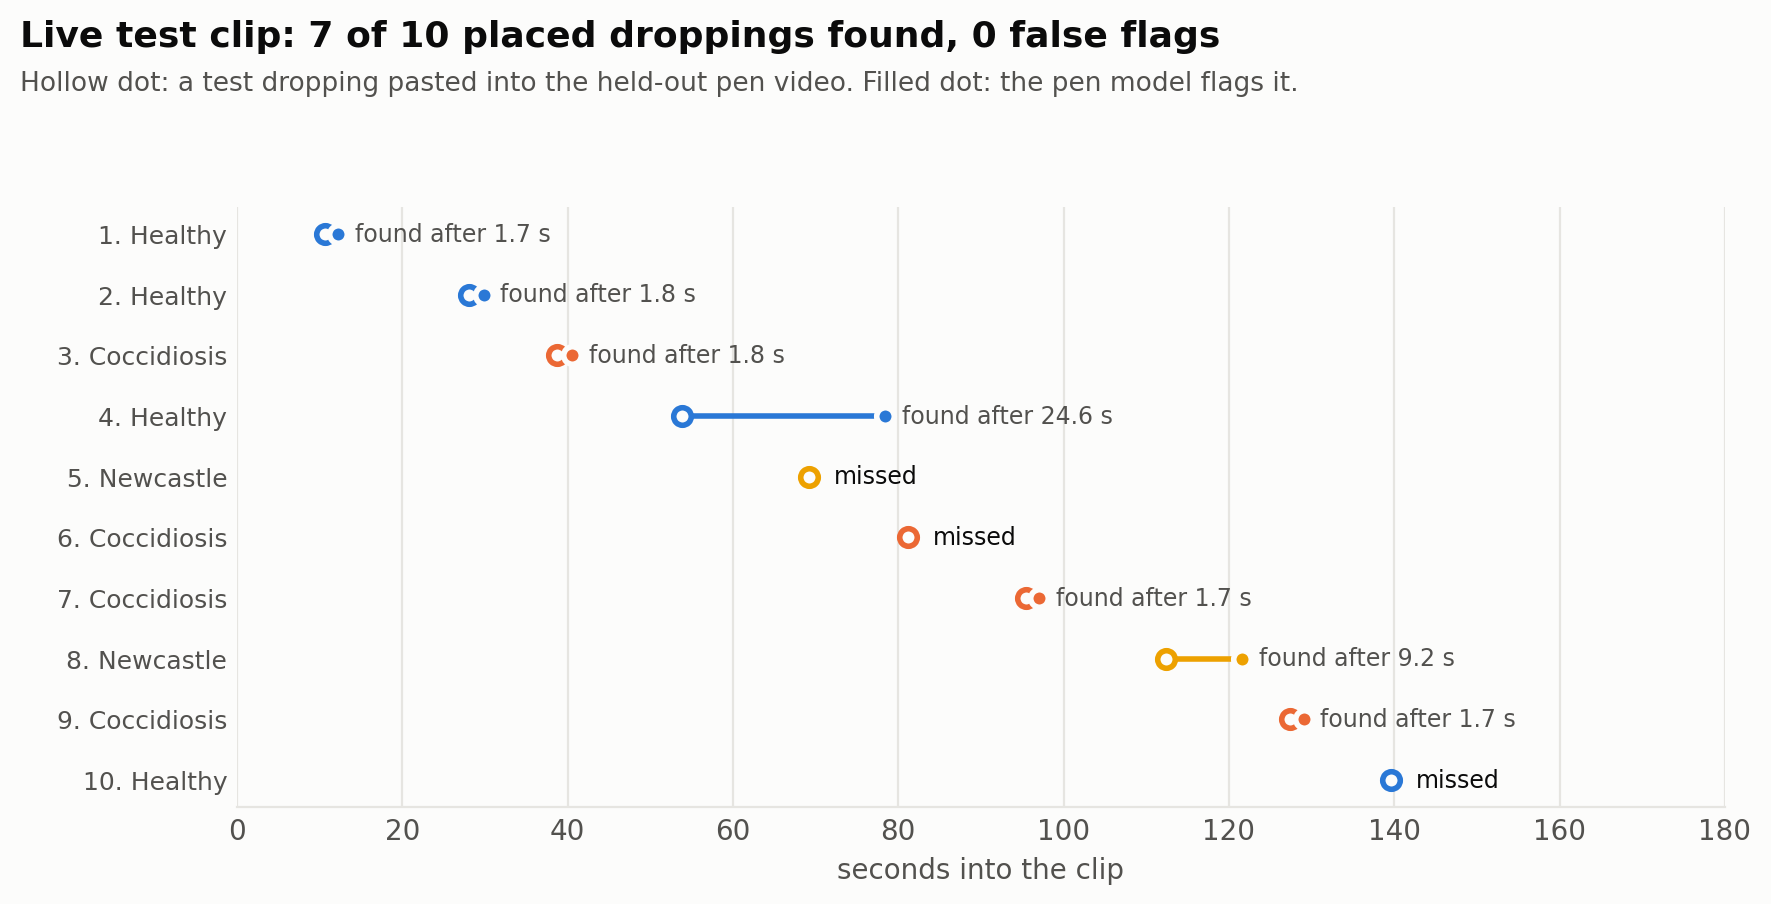

,class,placed at s,found at s,delay s
dropping,,,,
1,Healthy,10.6,12.27,1.67
2,Healthy,28.1,29.87,1.77
3,Coccidiosis-like,38.7,40.53,1.83
4,Healthy,53.8,78.40,24.60
5,Newcastle-like,69.2,NaN,NaN
6,Coccidiosis-like,81.2,NaN,NaN
7,Coccidiosis-like,95.4,97.07,1.67
8,Newcastle-like,112.4,121.60,9.20
9,Coccidiosis-like,127.4,129.07,1.67


In [9]:
t = ev.fig_live_clip(); show("12_live_clip_answer_key"); t

**Reading.** Three held-out minutes of the PIO camera behind Pen A1, with 10 test droppings pasted in at
known times, were read by the pen model at 2 frames a second with a short persistence rule, on the laptop. It flags
7, five of them within 2 seconds, and raises no false flags. One Newcastle-like, one coccidiosis-like and one healthy
dropping are missed. Ten pasted droppings is a small sample, so read it as a working demonstration, not a rate. On
the Pi the deployed pipeline works differently: a still-spot finder proposes candidates and the close-up detector
judges a full-resolution patch of each.

## 6. Against the classifiers earlier work used

Published accuracies on these photos come from other splits, so `training/benchmark_classifiers.py` retrains the
classifiers earlier papers used on our exact split and scores them on the same photos: MobileNetV2 (recommended by
Machuve et al.) for 20 epochs and EfficientNet-B0 (the classifier stage of Dhungana et al.) for 8, one seed each,
ImageNet pretrained, photos resized to 224 by 224. Classifiers always answer, so the detector is shown both with its
best guess always used and with the deployed 0.25 cut.

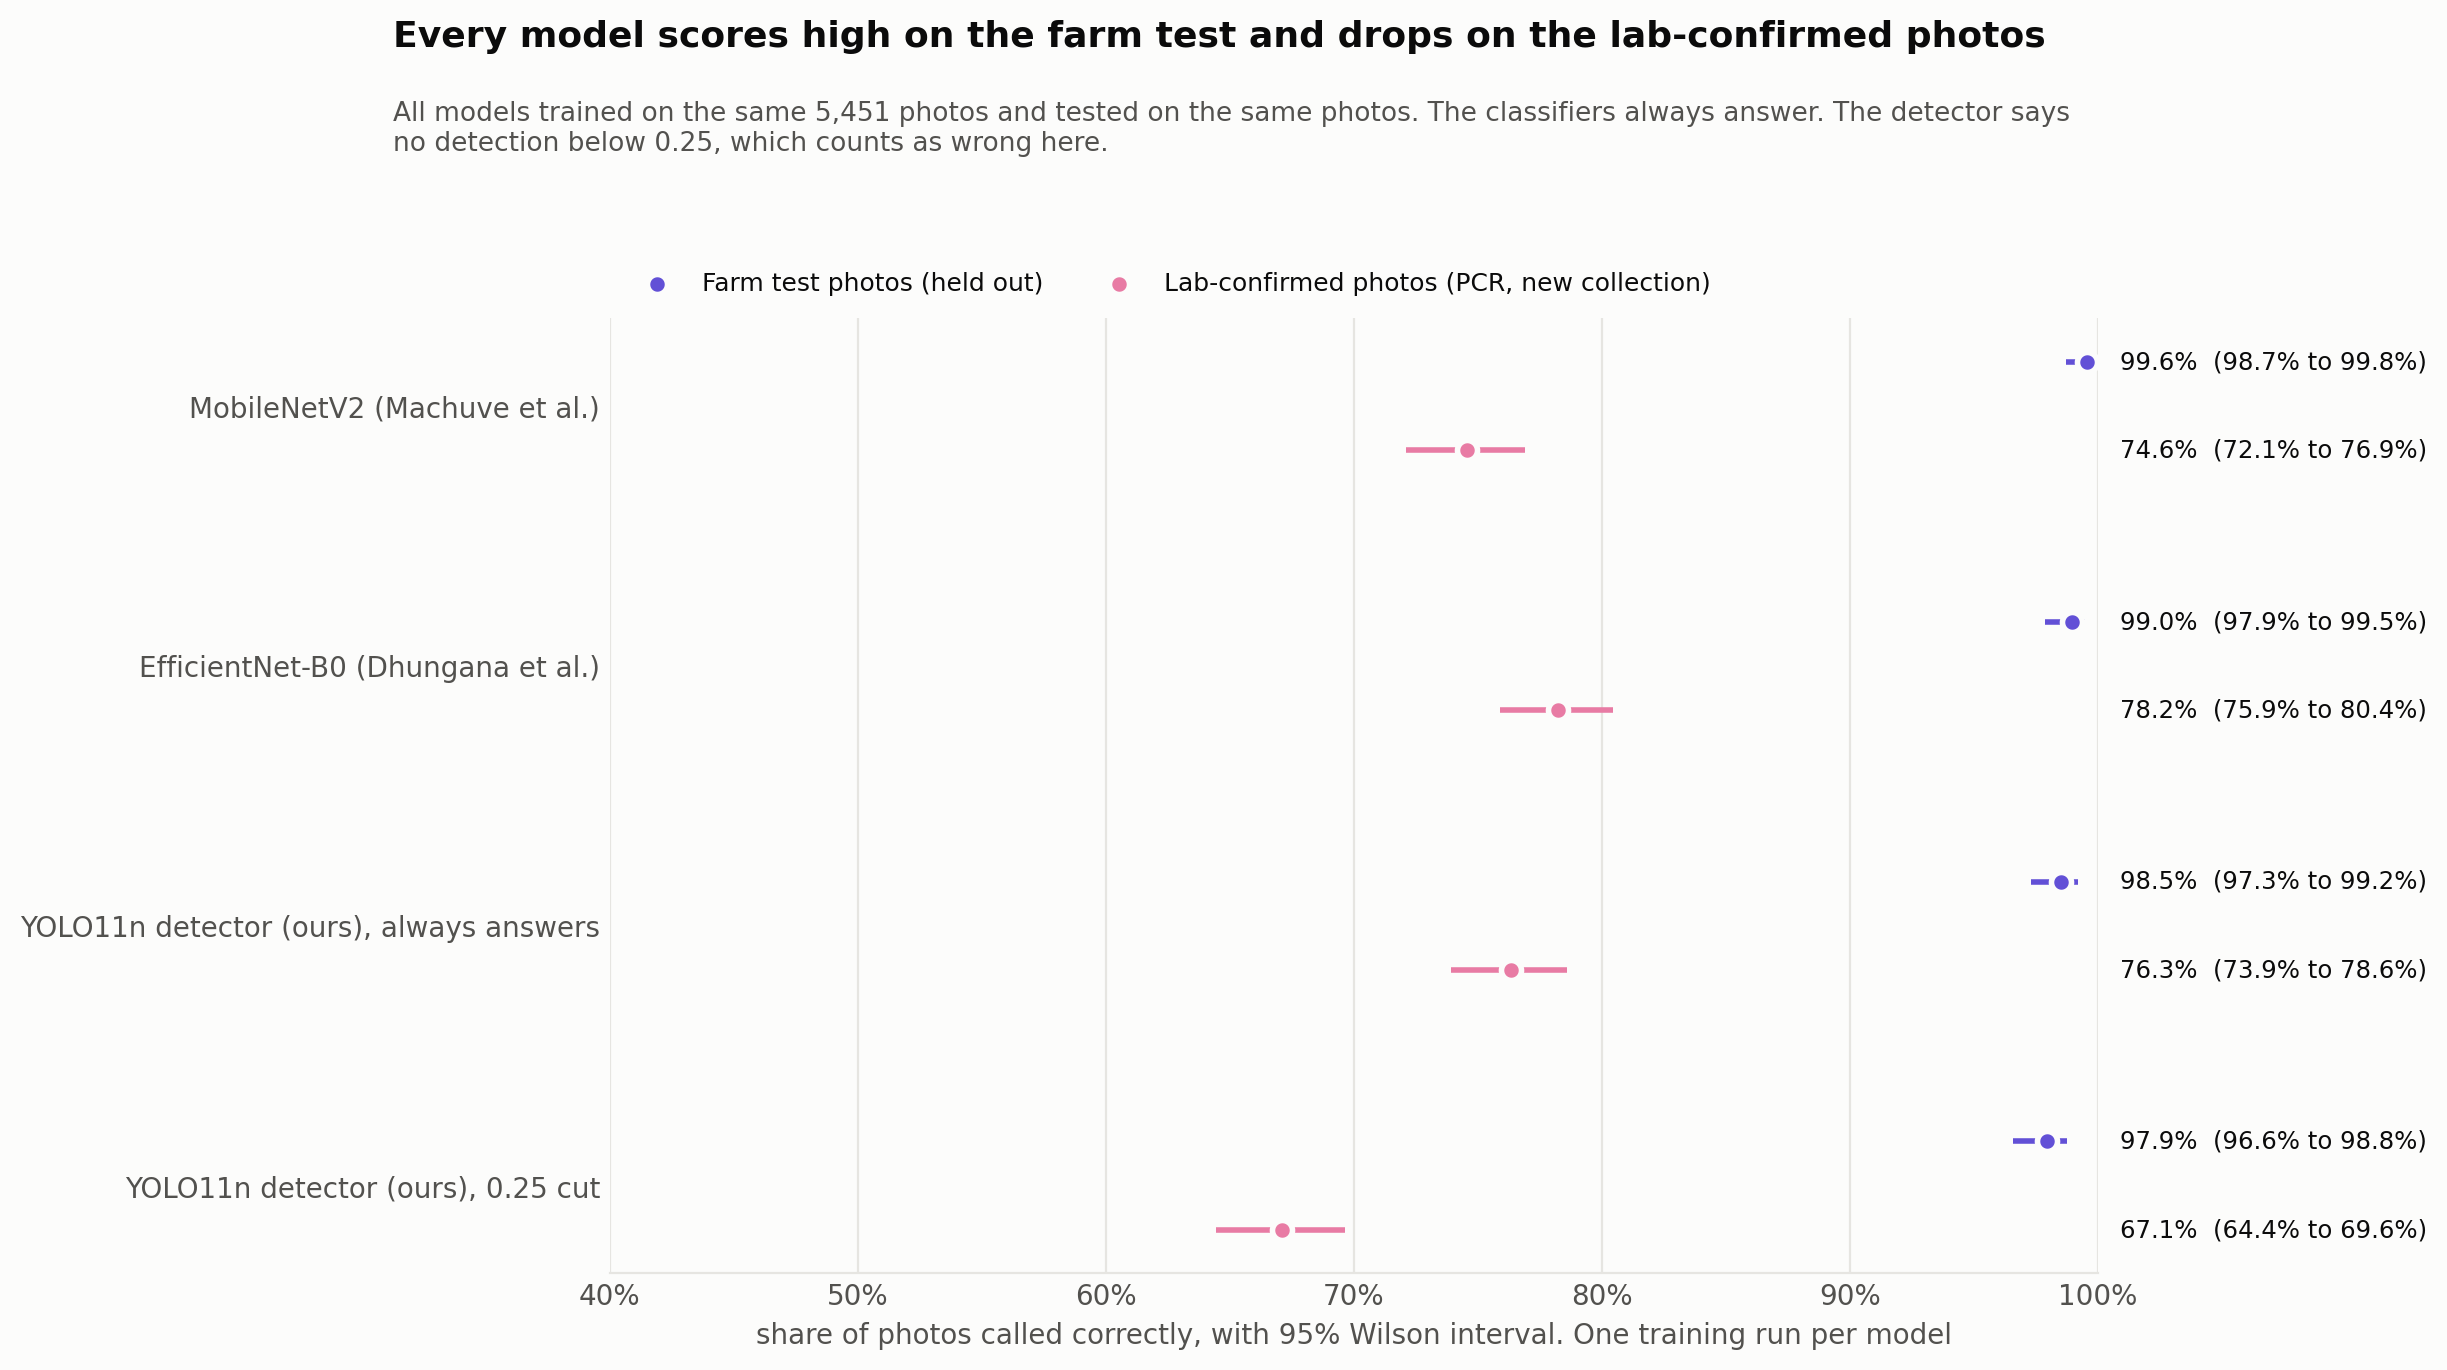

,model,set,seeds,accuracy,acc_min,acc_max,ci_low,ci_high,macro_f1,recall_ncd
0,efficientnet_b0,farm,1,0.990,0.990,0.990,0.979,0.995,0.986,0.973
1,efficientnet_b0,pcr,1,0.782,0.782,0.782,0.759,0.804,0.795,0.882
2,mobilenet_v2,farm,1,0.996,0.996,0.996,0.987,0.998,0.997,1.000
3,mobilenet_v2,pcr,1,0.746,0.746,0.746,0.721,0.769,0.753,0.699
4,yolo11n,farm,1,0.979,0.979,0.979,0.966,0.988,0.977,0.946
5,yolo11n,pcr,1,0.671,0.671,0.671,0.644,0.696,0.703,0.419
6,yolo11n_top,farm,1,0.985,0.985,0.985,0.973,0.992,0.983,0.973
7,yolo11n_top,pcr,1,0.763,0.763,0.763,0.739,0.786,0.751,0.527


In [10]:
s = ev.fig_benchmark(farm, pcr); show("13_benchmark"); s

**Reading.** Every model is at 98 to 99% on the farm test and drops by more than 20 points on the
lab-confirmed photos. Our detector is not a better classifier than these. The drop belongs to the data, not to one
architecture. What the detector adds is where the dropping is, which a pen camera needs.

## What this supports and what it does not

| Claim | Evidence | Verdict |
|---|---|---|
| The detector separates the four classes on photos like its training photos | 97.9% (96.6 to 98.8%) on 679 held-out farm photos | Supported |
| It does the same on new photos | 67.1% (64.4 to 69.6%) on 1,255 lab-confirmed photos | **Not supported** |
| The farm score is inflated by duplicates | 49 exact copies, removing them changes 97.9% to 97.8% | Not supported, the effect is small |
| Its confidence is a probability | Both sets sit above the diagonal | Not supported, it needs calibrating |
| It finds small droppings in pen video | pen fine-tune recall 0.80, precision 0.93, unseen cameras | Supported, on pasted droppings |
| It is a better classifier than earlier models | MobileNetV2 and EfficientNet-B0 retrained on the same split drop just as far | Not supported |
| It finds pasted droppings in a held-out pen clip | 7 of 10, 0 false flags | Demonstrated, small sample |